In [6]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Налаштування стилю графіків
sns.set_theme(style="darkgrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

1. Вступ та опис датасету

1.1. Назва, призначення та джерело даних

1.2. Опис набору даних

In [10]:
df = pd.read_csv('Data/credit_risk_dataset.csv')

print("=== РОЗМІРНІСТЬ ДАТАСЕТУ ===")
print(f"{df.shape[0]} рядків, {df.shape[1]} стовпчиків\n")

=== РОЗМІРНІСТЬ ДАТАСЕТУ ===
5000 рядків, 12 стовпчиків



In [9]:
# повна таблиця атрибутів
column_info = pd.DataFrame({
    'Назва атрибута': df.columns,
    'Тип даних': df.dtypes.astype(str).values,
    'Кількість заповнених': df.notnull().sum().values,
    'Пропущені значення': df.isnull().sum().values,
    'Унікальні значення': [df[col].nunique() for col in df.columns]
})

display(column_info)

,Назва атрибута,Тип даних,Кількість заповнених,Пропущені значення,Унікальні значення
0,person_age,int64,5000,0,48
1,person_income,int64,5000,0,1167
2,person_home_ownership,str,5000,0,4
3,person_emp_length,float64,4864,136,28
4,loan_intent,str,5000,0,6
5,loan_grade,str,5000,0,7
6,loan_amnt,int64,5000,0,386
7,loan_int_rate,float64,4516,484,272
8,loan_percent_income,float64,5000,0,67
9,cb_person_default_on_file,str,5000,0,2


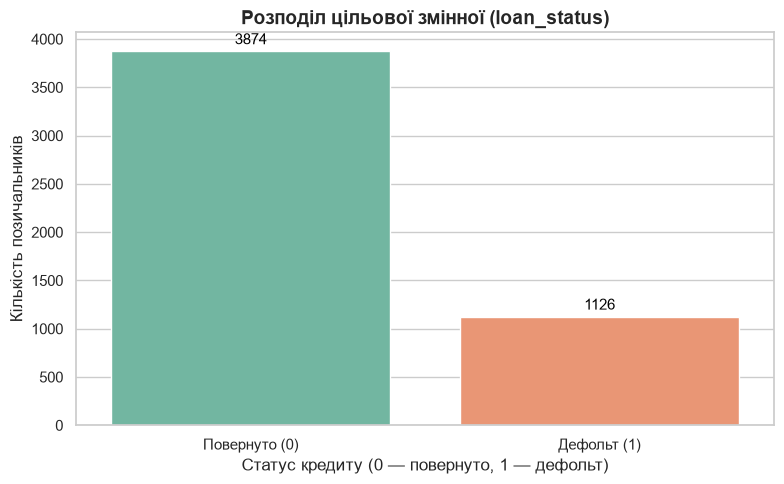

In [8]:
# Візуалізація розподілу цільової змінної (loan_status)
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='loan_status',
    hue='loan_status',
    palette='Set2',
    legend=False
)

plt.title('Розподіл цільової змінної (loan_status)', fontsize=14, fontweight='bold')
plt.xlabel('Статус кредиту (0 — повернуто, 1 — дефольт)', fontsize=12)
plt.ylabel('Кількість позичальників', fontsize=12)
plt.xticks([0, 1], ['Повернуто (0)', 'Дефольт (1)'])

# Додаємо цифри над стовпчиками
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='baseline',
        fontsize=11, color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

2. Розвідувальний аналіз даних (EDA)

2.1 Очищення даних та попередня обробка